# Лабораторна 2. Від сирих даних до нейромережі

У цій лабораторній роботі ви пройдете повний цикл роботи з табличним датасетом для задачі регресії — від завантаження до порівняння моделей:

- дослідницький аналіз даних (EDA): загальний огляд, гістограми, кореляції;
- обробка пропусків і викидів;
- інженерія ознак;
- baseline: множинна лінійна регресія;
- нейромережа — підбір архітектури, функцій активації, оптимізатора власними експериментами;
- чесне порівняння моделей на test за метриками регресії (MSE, RMSE, MAE, R²).

Демо-ноутбук з лекції 3-4 — основа, звертайтесь до нього як до довідника, коли щось незрозуміло.

## 0. Опрацюйте демо-ноутбук з лекції
Прогляньте пояснення ноутбуку і запустіть всі клітинки демо-ноутбуку (крім тих секцій, в яких вказано, що їх запускати не можна).
Після цього дайте тут відповідь на запитання:
1. Чому для заповнення пропусків було обрано метод kNN?
2. Чому при тренуванні лінійної регресії train і val порівнюються лише на основі MSE, а після тренування на основі багатьох функцій? Проекспериментуйте в межах тренування з вибором функції і поділіться результатами.
3. Які висновки після клітинки 2.6 в демо Ви можете зробити?
4. Поясни для чого потрібен baseline в лінійній регресії і як він вираховується? Що є baseline для нейронної мережі?
5. Продемонструй дію всіх функцій активації на графіку функцій, згенерувавши 1000 випадкових значень Х і порахувавши для них Y через ці функції.
6. Яким чином в нейронній мережі утворилася така кількість параметрів, яка вказана після виконання 3.3?
7. Чи оптимально вибрано кількість епох в 3.5?

### 0.1 Мої відповіді:
1. Метод kNN (k-найближчих сусідів) було обрано тому, що він враховує складні багатовимірні зв'язки та залежності між іншими ознаками об'єкта, на відміну від простих методів (заповнення медіаною чи середнім). Прості методи обчислюють статистику ізольовано для кожної колонки й ігнорують контекст. kNN знаходить у просторі ознак $k$ найбільш схожих за іншими параметрами записів і прогнозує пропущене значення на їхній основі, що зберігає природний розподіл даних. При цьому, щоб уникнути data leakage, модель kNN тренується виключно на train, після чого лише застосовується до val та test.

2. Під час тренування оптимізатору (SGD/Adam) потрібна диференційована функція втрат (Loss Function) з гладкими градієнтами, якою є MSE. Зручно контролювати процес за однією основною метрикою, під яку оптимізується модель.
Після тренування: Метрики оцінюються для людини та бізнес-інтерпретації. RMSE повертає помилку у початкових одиницях вимірювання целевої змінної, MAE показує середнє абсолютне відхилення й менш чутлива до викидів, а $R^2$ описує частку поясненої дисперсії (відносно бейзлайну).
Якщо змінити функцію втрат під час тренування з MSE (nn.MSELoss) на MAE (nn.L1Loss), модель оптимізує медіану замість середнього. Це робить градієнти стабільнішими до викидів, але збіжність біля оптимуму уповільнюється (через постійний модуль градієнта), і фінальне значення MSE на val зазвичай виходить трохи гіршим, хоча MAE може незначно покращитися.

3. Оскільки перед тренуванням усі ознаки були приведені до єдиного масштабу через StandardScaler (з нульовим середнім та одиничною дисперсією), коефіцієнти лінійної моделі можна порівнювати між собою напряму. Найсильнішим позитивним фактором виявився середній дохід населення (MedInc з вагою близько $+0.827$), що цілком логічно для вартості нерухомості. Також високу ефективність показала спроектована ознака diag_coord з коефіцієнтом $-0.304$, що підтвердило доцільність її створення для врахування географічного розташування. Відношення спалень до загальної кількості кімнат (bedperroom) дало вагу близько $+0.198$, виявившись кориснішим за вихідні окремі колонки. Водночас деякі параметри, як-от розмір населення (Population із вагою $-0.0017$), у лінійному наближенні практично не впливають на кінцевий прогноз ціни.


4. Бейзлайн у лінійній регресії слугує найпростішим орієнтиром якості, від якого вимірюється користь будь-якої моделі. Він обчислюється як банальне константне значення — середнє по цільовій змінній з навчальної вибірки (y_train.mean()). Якщо лінійна модель не здатна обігнати цей тривіальний прогноз і видає $R^2 \le 0$, це свідчить про її повну непридатність або проблеми з даними. У випадку ж нейронної мережі роль бейзлайну виконує вже натренована лінійна регресія. Вона встановлює планку того, що можна витиснути з даних звичайними лінійними комбінаціями, і якщо нейромережа не показує кращого результату, це сигналізує про перенавчання чи неефективну архітектуру.

5. Під цим блоком.

6. Сумарна кількість у 2625 параметрів складається з вагових коефіцієнтів та зсувів (bias) кожної лінійної трансформації. На першому шарі Linear(7, 64) маємо 7 вхідних ознак, які множаться на 64 нейрони (448 ваг) плюс 64 зсуви, що разом дає 512 параметрів. Другий прихований шар Linear(64, 32) приймає 64 значення й видає 32, генеруючи $64 \times 32 = 2048$ ваг та 32 зсуви (разом 2080). Останній вихідний шар Linear(32, 1) перетворює 32 значення в один прогноз ціни, додаючи ще 32 ваги та 1 зсув (разом 33). Додавши параметри всіх трьох шарів ($512 + 2080 + 33$), ми й отримуємо підсумкові 2625 навчальних параметрів.

7. Обрана кількість у 200 епох є близькою до оптимальної, хоча не вичерпує потенціал моделі повністю. Графік кривої навчання свідчить про правильний хід тренування: втрати на навчальній та валідаційній вибірках зменшуються паралельно без вираженого перенавчання (overfitting). Разом з тим, на останніх епохах крива val_loss все ще зберігає невеликий нахил донизу, трохи зменшуючись навіть між 160-ю та 200-ю епохами (з ~0.3803 до ~0.3711). Це говорить про те, що процес можна було б продовжити ще на 100–200 епох із використанням Early Stopping для досягнення повного плато.


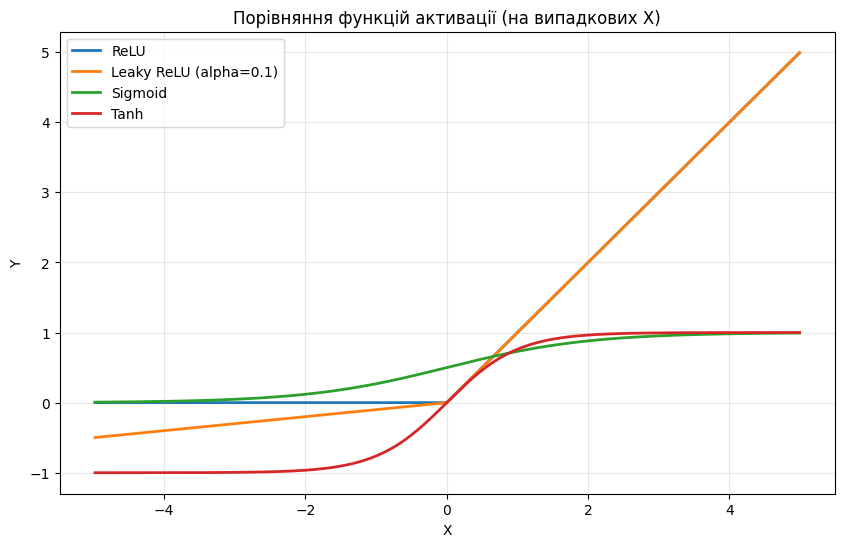

In [3]:
# 5.

import torch
import matplotlib.pyplot as plt

x_raw = torch.empty(1000).uniform_(-5, 5)
x, _ = torch.sort(x_raw)

relu = torch.relu(x)
leaky_relu = torch.nn.functional.leaky_relu(x, negative_slope=0.1)
sigmoid = torch.sigmoid(x)
tanh = torch.tanh(x)

# 4. Побудова графіка
plt.figure(figsize=(10, 6))
plt.plot(x.numpy(), relu.numpy(), label='ReLU', linewidth=2)
plt.plot(x.numpy(), leaky_relu.numpy(), label='Leaky ReLU (alpha=0.1)', linewidth=2)
plt.plot(x.numpy(), sigmoid.numpy(), label='Sigmoid', linewidth=2)
plt.plot(x.numpy(), tanh.numpy(), label='Tanh', linewidth=2)

plt.title('Порівняння функцій активації (на випадкових X)')
plt.xlabel('X')
plt.ylabel('Y')
plt.grid(True, alpha=0.3)
plt.legend()
plt.show()

---
## 1. Датасети

Ви отримаєте один з 10 датасетів нижче. Усі — задачі регресії на Hugging Face: табличні дані, здебільшого числові ознаки, від кількасот до кількадесяти тисяч рядків.

1. **[King County House Sales](https://huggingface.co/datasets/kraina/house_sales_in_king_county)** — 21 613 продажів будинків (Вашингтон, 2014–2015). Таргет: `price`. ⚠️ `load_dataset("kraina/house_sales_in_king_county")` не працює (застарілий loading-скрипт) — вантажте напряму: `load_dataset("parquet", data_files="https://huggingface.co/datasets/kraina/house_sales_in_king_county/resolve/main/data/house_sales_king_county.parquet")`.
2. **[Diamonds](https://huggingface.co/datasets/jdxcosta/diamonds)** — 53 940 діамантів. Таргет: `price`. Ознаки: вага (`carat`), огранка, колір, чистота, розміри.
3. **[Concrete Compressive Strength](https://huggingface.co/datasets/foundry-ml/dataset_concrete_compressive_strength)** — 1 030 замісів бетону. Таргет: міцність на стиск. Усі ознаки числові (склад суміші + вік).
4. **[Auto MPG](https://huggingface.co/datasets/scikit-learn/auto-mpg)** — 398 автомобілів. Таргет: `mpg` (витрата пального). Найменший і найпростіший датасет зі списку.
5. **[Wine Quality](https://huggingface.co/datasets/codesignal/wine-quality)** — 1 599 (червоне) + 4 898 (біле) вин. Таргет: `quality` (оцінка 3–9). Усі ознаки — хімічний склад, числові.
6. **[Laptop Price](https://huggingface.co/datasets/Ammok/laptop_price_prediction)** — 977 + 325 ноутбуків. Таргет: `Price`. Частина ознак текстові (`RAM`, `Storage`, `CPU`) — доведеться парсити в числа.
7. **[Bike Sharing Demand](https://huggingface.co/datasets/t22000t/bike-sharing-tabular)** — 17 379 годинних записів прокату велосипедів. Таргет: `cnt`. Часові й погодні ознаки.
8. **[Ames House Prices](https://huggingface.co/datasets/t22000t/house-prices-tabular)** — 1 460 будинків, 79 ознак. Таргет: `SalePrice`. Найбільше категоріальних ознак зі списку — гарна практика на encoding.
9. **[Medical Insurance Cost](https://huggingface.co/datasets/harishsohani/medical-insurance-cost-prediction)** — 1 338 застрахованих. Таргет: `charges`. Компактний, мало ознак — хороший старт, якщо часу мало. ⚠️ У репозиторії кілька CSV одразу (`Xtrain`/`Xtest`/`insurance.csv`) — вкажіть файл явно: `load_dataset("harishsohani/medical-insurance-cost-prediction", data_files="insurance.csv")`.
10. **[Abalone](https://huggingface.co/datasets/mstz/abalone)** — 4 177 молюсків. Таргет: `number_of_rings` (вік). Усі ознаки — фізичні виміри, окрім `sex`.

Решта (2–5, 7–8, 10) вантажаться напряму — `load_dataset("<repo_id>")` без додаткових аргументів, HF-токен не потрібен.

### 1.1. Який датасет мій?

Визначте самі власний датасет: беремо Ваше ПІБ, рахуємо SHA-256 хеш, залишок від ділення на 10 — це індекс у списку датасетів вище (0 → перший, 9 → останній).

**Формат ПІБ:** точно як у списку групи — `Прізвище Ім'я По-батькові`, по одному пробілу між словами, без зайвих пробілів на початку/в кінці. Якщо використаєте інший формат - **не зарахую лабу**!!!

In [4]:
import hashlib

DATASETS = [
    "King County House Sales",
    "Diamonds",
    "Concrete Compressive Strength",
    "Auto MPG",
    "Wine Quality",
    "Laptop Price",
    "Bike Sharing Demand",
    "Ames House Prices",
    "Medical Insurance Cost",
    "Abalone",
]

FULL_NAME = "Карпінський Олександр Сергійович"

dataset_index = int(hashlib.sha256(FULL_NAME.encode("utf-8")).hexdigest(), 16) % len(DATASETS)
print(f"Ваш датасет (#{dataset_index + 1}):", DATASETS[dataset_index])

Ваш датасет (#7): Bike Sharing Demand


---
## 2. Що потрібно зробити

Нижче — загальний план роботи, без коду: код і пояснення до кожного кроку дивіться в **демо-ноутбуці лекції 3-4**, номери розділів позначені в дужках. Ваша задача — повторити той самий підхід на своєму датасеті, а не скопіювати код один в один: у вашого датасету інші колонки, інші типи пропусків (чи їх взагалі нема), інші викиди (чи їх нема) — рішення на кожному кроці обґрунтовуйте під свої дані, а не тому, що "так було в демо".

### 2.1. Підготовка даних

1. Завантажте свій датасет (демо 1.1) і перетворіть на `pandas.DataFrame` (1.2).
2. Зробіть спліт **train / val / test** одразу, до будь-якого аналізу (1.3) — і поясніть своїми словами, чому саме в такому порядку (нагадування: data leakage).
3. Загальний огляд (`head`/`info`/`describe`, 1.4).
4. Обробка пропусків (1.5) — **якщо вони є**. Немає пропусків — так і напишіть, це теж валідний результат, не треба їх штучно вигадувати.
5. EDA (1.6): хоча б гістограми і кореляційна матриця. Що впадає в очі у ваших даних — capping, скошені розподіли, мультиколінеарність?
6. Обробка викидів (1.7) — **за потреби**, з обґрунтуванням: звідки взявся викид і чому саме таке рішення (видалити / трансформувати / залишити).
7. Інженерія ознак (1.8) — **за потреби**: чи є сенс комбінувати/прибирати ознаки з високою кореляцією між собою.

### 2.2. Baseline: множинна лінійна регресія

Стандартизація ознак (2.1), тензори (2.2), тренування `nn.Linear` (2.3), крива навчання (2.4), метрики на test — MSE/RMSE/MAE/R² (2.5), інтерпретація ваг (2.6).

Це ваш **варіант #1**, точка відліку для всього, що далі.

### 2.3. Нейромережа: щонайменше 2 різні архітектури

За зразком розділу 3 демо: `nn.Sequential` з прихованими шарами, ReLU, оптимізатор Adam.

Спробуйте **мінімум 2 архітектури**, які відрізняються не косметично — напр. різна кількість шарів, різна ширина шарів, чи інша функція активації (3.2). Кожна — окремий варіант.

### 2.4. Підбір гіперпараметрів: щонайменше 3 зміни

Візьміть архітектуру, яка показала себе краще, і поекспериментуйте з гіперпараметрами: learning rate, оптимізатор (SGD/Adam), кількість епох, розмір batch (якщо вирішите його ввести) тощо. Змінюйте **по одному параметру за раз** — інакше не зрозумієте, що саме вплинуло на результат.

**Разом (2.2 + 2.3 + 2.4):** щонайменше 5 варіантів моделі (1 лінійна + 2 архітектури + 2 гіперпараметри), до **10 варіантів** — якщо є час і бажання поекспериментувати більше, це тільки заохочується.

### 2.5. Логування і порівняння

Кожен варіант (2.2-2.4) логуйте в TensorBoard в окрему підпапку `RUNS_DIR` (як у 2.3/3.5 демо) — з осмисленою назвою (`linear`, `nn_v1_2layers`, `nn_v2_deeper`, `nn_v2_lr_0.001`, ...), щоб потім усі криві можна було накласти одна на одну (3.8 демо) і візуально порівняти.

Наприкінці зведіть усі варіанти в одну таблицю (модель → MSE/RMSE/MAE/R² на test) і дайте коротку письмову відповідь:
- Яка модель перемогла і наскільки суттєво?
- Чи виправдала себе нейромережа порівняно з лінійною регресією на вашому датасеті?
- Що з ваших змін (архітектура чи гіперпараметри) дало найбільший ефект?

In [5]:
# 2.1.1. Завантаження датасету та перетворення на датафрейм

!pip install -q datasets
from datasets import load_dataset

raw_dataset = load_dataset("t22000t/bike-sharing-tabular")
df = raw_dataset["train"].to_pandas()
print(f"Загальний розмір датасету: {df.shape}")

README.md:   0%|          | 0.00/5.44k [00:00<?, ?B/s]

hour.csv:   0%|          | 0.00/1.16M [00:00<?, ?B/s]

Generating train split:   0%|          | 0/17379 [00:00<?, ? examples/s]

Загальний розмір датасету: (17379, 17)


In [6]:
# 2.1.2. Спліт train(60%) / val(20%) / test(20%)

from sklearn.model_selection import train_test_split

SEED = 42

# Відокремлюємо train (60%) від решти (40%)
train_df, temp_df = train_test_split(df, test_size=0.4, random_state=SEED)

# Решту 40% ділимо порівну на val (20%) та test (20%)
val_df, test_df = train_test_split(temp_df, test_size=0.5, random_state=SEED)

print(f"Розмір навчальної вибірки (train): {train_df.shape}")
print(f"Розмір валідаційної вибірки (val):   {val_df.shape}")
print(f"Розмір тестової вибірки (test):    {test_df.shape}")

Розмір навчальної вибірки (train): (10427, 17)
Розмір валідаційної вибірки (val):   (3476, 17)
Розмір тестової вибірки (test):    (3476, 17)


Розподіл даних на навчальну, валідаційну та тестову вибірки здійснюється одразу після завантаження для запобігання витоку інформації (data leakage). Будь-які статистичні обчислення (середнє, медіани для пропусків, нормалізація StandardScaler або виявлення аномалій) повинні розраховуватись виключно на навчальній вибірці train. Якщо проводити препроцесинг на всьому датасеті до розподілу, статистики з валідаційного та тестового наборів викривлять оцінку і зроблять її нечесно оптимістичною.

In [8]:
# 2.1.3. Загальний огляд (head / info / describe)

# Перші рядки
train_df.head()

# Типи колонок та пропуски
train_df.info()

# Базова статистика
train_df.describe()

<class 'pandas.core.frame.DataFrame'>
Index: 10427 entries, 3219 to 15795
Data columns (total 17 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   instant     10427 non-null  int64  
 1   dteday      10427 non-null  object 
 2   season      10427 non-null  int64  
 3   yr          10427 non-null  int64  
 4   mnth        10427 non-null  int64  
 5   hr          10427 non-null  int64  
 6   holiday     10427 non-null  int64  
 7   weekday     10427 non-null  int64  
 8   workingday  10427 non-null  int64  
 9   weathersit  10427 non-null  int64  
 10  temp        10427 non-null  float64
 11  atemp       10427 non-null  float64
 12  hum         10427 non-null  float64
 13  windspeed   10427 non-null  float64
 14  casual      10427 non-null  int64  
 15  registered  10427 non-null  int64  
 16  cnt         10427 non-null  int64  
dtypes: float64(4), int64(12), object(1)
memory usage: 1.4+ MB


,instant,season,yr,mnth,hr,holiday,weekday,workingday,weathersit,temp,atemp,hum,windspeed,casual,registered,cnt
count,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000,10427.000000
mean,8710.134459,2.510118,0.503596,6.551165,11.586171,0.026949,3.002302,0.680253,1.430133,0.497923,0.476946,0.627487,0.189765,35.925386,155.554714,191.480100
std,5025.028573,1.104274,0.500011,3.429533,6.920372,0.161943,2.014953,0.466401,0.641150,0.192727,0.172060,0.193257,0.122121,49.264070,153.104534,183.072824
min,2.000000,1.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,1.000000,0.020000,0.000000,0.000000,0.000000,0.000000,0.000000,1.000000
25%,4362.500000,2.000000,0.000000,4.000000,6.000000,0.000000,1.000000,0.000000,1.000000,0.340000,0.333300,0.480000,0.104500,4.000000,34.000000,40.000000
50%,8714.000000,3.000000,1.000000,7.000000,12.000000,0.000000,3.000000,1.000000,1.000000,0.500000,0.484800,0.630000,0.164200,17.000000,118.000000,145.000000
75%,13066.500000,3.000000,1.000000,10.000000,18.000000,0.000000,5.000000,1.000000,2.000000,0.660000,0.621200,0.790000,0.253700,49.000000,222.000000,282.000000
max,17379.000000,4.000000,1.000000,12.000000,23.000000,1.000000,6.000000,1.000000,4.000000,1.000000,0.984800,1.000000,0.850700,367.000000,885.000000,976.000000


In [9]:
# 2.1.4. Обробка пропусків

print("Кількість пропусків у train_df:")
print(train_df.isna().sum())

Кількість пропусків у train_df:
instant       0
dteday        0
season        0
yr            0
mnth          0
hr            0
holiday       0
weekday       0
workingday    0
weathersit    0
temp          0
atemp         0
hum           0
windspeed     0
casual        0
registered    0
cnt           0
dtype: int64


Пропуски відсутні.

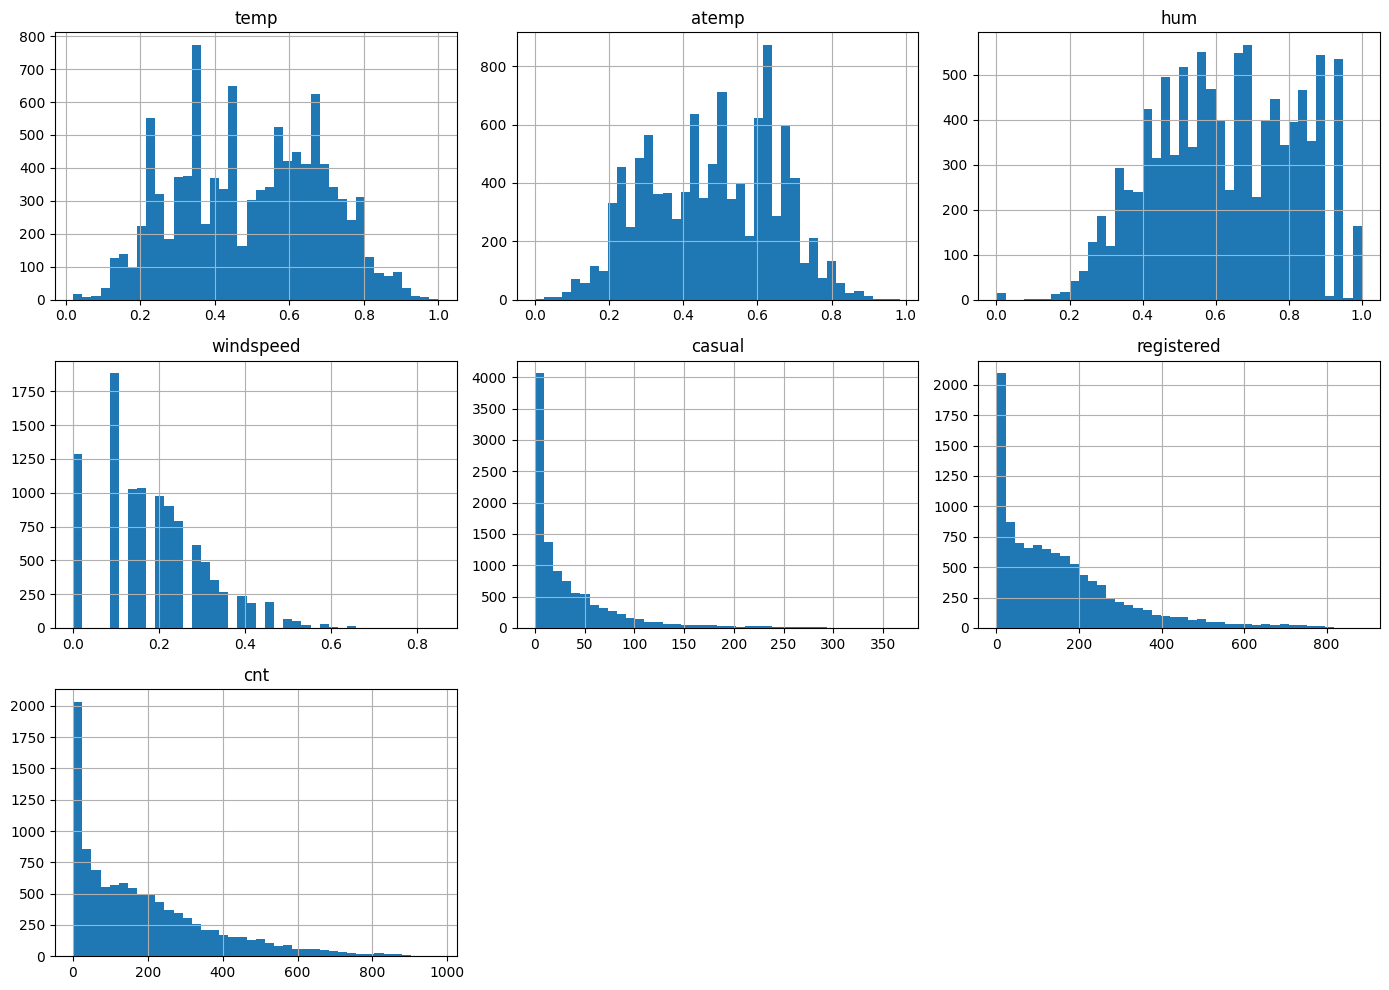

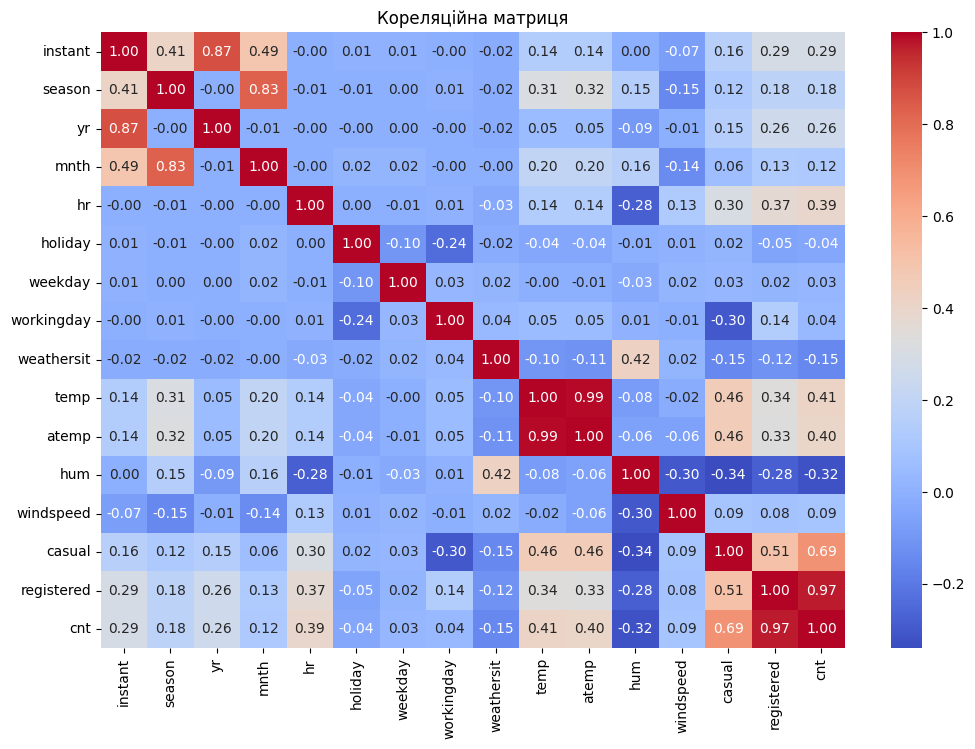

In [10]:
# 2.1.5. Дослідницький аналіз даних (EDA)

import matplotlib.pyplot as plt
import seaborn as sns

# 1. Гістограми основних числових ознак та таргету
train_df[['temp', 'atemp', 'hum', 'windspeed', 'casual', 'registered', 'cnt']].hist(bins=40, figsize=(14, 10))
plt.tight_layout()
plt.show()

# 2. Кореляційна матриця (виключаємо dteday)
plt.figure(figsize=(12, 8))
numeric_cols = train_df.select_dtypes(include=['int64', 'float64']).columns
corr = train_df[numeric_cols].corr().round(2)
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt=".2f", cbar=True)
plt.title("Кореляційна матриця")
plt.show()

Таргет cnt має сильну правосторонню асиметрію, оскільки більшість часу попит невеликий, але присутні різкі піки в окремі години. Схожий скос спостерігається і для колонок windspeed, casual та registered.
Штучного обрізання значень (capping) у даних немає, а показники температури та вологості розподілені цілком природно.
Присутня серйозна мультиколінеарність і витік даних: temp та atemp майже повністю дублюють один одного з кореляцією 0.99, таргет cnt є прямою сумою casual + registered (що дає витік інформації), а порядковий індекс instant сильно корелює з роком та місяцем.

**2.1.6 Обробка викидів**

В аналізованому датасеті спостерігаються значні пікові значення цільової змінної cnt у графіках гістограм. Проте ці значення не є помилками збору даних чи технічними збоями — вони відображають реальні сплески попиту на прокат велосипедів у години пік, свята або дні з ідеальними погодними умовами. Видалення таких рядків викривило б реальну картину попиту та позбавило б модель здатності прогнозувати високе навантаження. З огляду на це рішення щодо обробки викидів полягає у їх збереженні в оригінальному вигляді, а стійкість моделей забезпечується подальшою стандартизацією ознак StandardScaler та вибором відповідних гіперпараметрів.

In [11]:
# 2.1.7. Інженерія ознак

# Функція для очищення та інженерії ознак
def process_features(df):
    df_out = df.copy()

    # Список колонок для видалення (витік даних, дублювання, технічні індекси)
    cols_to_drop = ['instant', 'casual', 'registered', 'atemp', 'dteday']

    # Видаляємо лише ті, які є в dataframe
    df_out = df_out.drop(columns=[c for c in cols_to_drop if c in df_out.columns])

    return df_out

# Застосовуємо однаково до train, val і test для збереження структури
train_df_proc = process_features(train_df)
val_df_proc = process_features(val_df)
test_df_proc = process_features(test_df)

print("Розмірність train після інженерії ознак:", train_df_proc.shape)
print("Фінальний список ознак для навчання:")
print(list(train_df_proc.columns))

Розмірність train після інженерії ознак: (10427, 12)
Фінальний список ознак для навчання:
['season', 'yr', 'mnth', 'hr', 'holiday', 'weekday', 'workingday', 'weathersit', 'temp', 'hum', 'windspeed', 'cnt']


На основі виявленої кореляції та аналізу витоку даних робимо очищення та трансформацію ознак.

Видалення casual та registered: Оскільки casual + registered = cnt, ці колонки утворюють прямий витік даних (data leakage) і їх збереження призвело б до тривіального перенавчання.

Усунення мультиколінеарності (atemp): Ознака atemp корелює з temp на рівні $0.99$, тобто повністю дублює інформацію про температуру. Для спрощення моделі та уникнення дублювання ваг залишаємо лише temp.

Вилучення індексу instant та дати dteday: Колонка instant є лише порядковим номером запису, який сильно корелює з часом. Текстову дату dteday також прибираємо, адже наявні колонки yr, mnth, hr та weekday уже вичерпно кодують часові параметри.

In [12]:
# 2.2.1. Стандартизація ознак та конвертація в PyTorch-тензори

import torch
import torch.nn as nn
from sklearn.preprocessing import StandardScaler

# Перевірка GPU
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

# 1. Формуємо список ознак (без таргету cnt)
feature_cols = [c for c in train_df_proc.columns if c != 'cnt']

# 2. Масштабування ознак
scaler = StandardScaler()
X_train = scaler.fit_transform(train_df_proc[feature_cols])
X_val = scaler.transform(val_df_proc[feature_cols])
X_test = scaler.transform(test_df_proc[feature_cols])

y_train = train_df_proc['cnt'].values
y_val = val_df_proc['cnt'].values
y_test = test_df_proc['cnt'].values

# 3. Функція перетворення в PyTorch-тензори
def to_tensor(X, y):
    return (
        torch.tensor(X, dtype=torch.float32).to(device),
        torch.tensor(y, dtype=torch.float32).unsqueeze(1).to(device)
    )

x_train_t, y_train_t = to_tensor(X_train, y_train)
x_val_t, y_val_t = to_tensor(X_val, y_val)
x_test_t, y_test_t = to_tensor(X_test, y_test)

print(f"Форма X_train_t: {x_train_t.shape}")
print(f"Форма y_train_t: {y_train_t.shape}")

Форма X_train_t: torch.Size([10427, 11])
Форма y_train_t: torch.Size([10427, 1])


In [13]:
# 2.2.2. Тренування nn.Linear та логування у TensorBoard

import os
from google.colab import drive
from torch.utils.tensorboard import SummaryWriter

drive.mount("/content/drive")
BASE_DIR = "/content/drive/MyDrive/ai_systems/lab2"

MODELS_DIR = os.path.join(BASE_DIR, "models")
RUNS_DIR = os.path.join(BASE_DIR, "runs")
os.makedirs(MODELS_DIR, exist_ok=True)
os.makedirs(RUNS_DIR, exist_ok=True)

N_EPOCHS = 100
n_features = x_train_t.shape[1]

# Ініціалізація лінійної моделі
linear_model = nn.Linear(in_features=n_features, out_features=1).to(device)
optimizer = torch.optim.SGD(linear_model.parameters(), lr=0.05)
loss_fn = nn.MSELoss()

writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, "linear_regression"))

train_losses, val_losses = [], []

for epoch in range(N_EPOCHS):
    linear_model.train()
    optimizer.zero_grad()
    y_pred = linear_model(x_train_t)
    loss = loss_fn(y_pred, y_train_t)
    loss.backward()
    optimizer.step()
    train_losses.append(loss.item())

    linear_model.eval()
    with torch.no_grad():
        val_loss = loss_fn(linear_model(x_val_t), y_val_t).item()
    val_losses.append(val_loss)

    writer.add_scalar("Loss/train", loss.item(), epoch)
    writer.add_scalar("Loss/val", val_loss, epoch)

    if epoch % 10 == 0 or epoch == N_EPOCHS - 1:
        print(f"Epoch {epoch:3d} | Train Loss: {loss.item():.2f} | Val Loss: {val_loss:.2f}")

writer.close()

# Зберігаємо чекпоїнт
torch.save(linear_model.state_dict(), os.path.join(MODELS_DIR, "linear.pt"))

Mounted at /content/drive
Epoch   0 | Train Loss: 70144.92 | Val Loss: 57537.97
Epoch  10 | Train Loss: 25725.84 | Val Loss: 23385.21
Epoch  20 | Train Loss: 21168.62 | Val Loss: 19880.91
Epoch  30 | Train Loss: 20626.90 | Val Loss: 19493.38
Epoch  40 | Train Loss: 20556.95 | Val Loss: 19455.58
Epoch  50 | Train Loss: 20545.92 | Val Loss: 19454.64
Epoch  60 | Train Loss: 20543.00 | Val Loss: 19456.20
Epoch  70 | Train Loss: 20541.58 | Val Loss: 19457.27
Epoch  80 | Train Loss: 20540.68 | Val Loss: 19457.96
Epoch  90 | Train Loss: 20540.05 | Val Loss: 19458.44
Epoch  99 | Train Loss: 20539.65 | Val Loss: 19458.78


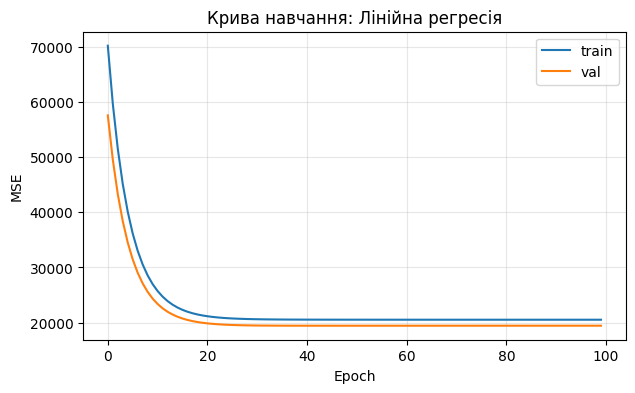

Baseline (Mean)    | MSE:   31462.36 | RMSE:   177.38 | MAE:   139.81 | R2: -0.0012
Linear Regression  | MSE:   19667.20 | RMSE:   140.24 | MAE:   106.18 | R2:  0.3742


In [22]:
# 2.2.3. Крива навчання та метрики на Test

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

# 1. Графік кривих навчання
plt.figure(figsize=(7, 4))
plt.plot(train_losses, label="train")
plt.plot(val_losses, label="val")
plt.xlabel("Epoch")
plt.ylabel("MSE")
plt.title("Крива навчання: Лінійна регресія")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

# 2. Обчислення прогнозів
linear_model.eval()
with torch.no_grad():
    y_test_pred = linear_model(x_test_t).cpu().numpy().flatten()

baseline_pred = np.full_like(y_test, y_train.mean())

# 3. Звіт по метриках
all_results = []

def report(y_true, y_pred, name):
    mse = mean_squared_error(y_true, y_pred)
    rmse = np.sqrt(mse)
    mae = mean_absolute_error(y_true, y_pred)
    r2 = r2_score(y_true, y_pred)
    print(f"{name:18s} | MSE: {mse:10.2f} | RMSE: {rmse:8.2f} | MAE: {mae:8.2f} | R2: {r2:7.4f}")
    return {"Model": name, "MSE": mse, "RMSE": rmse, "MAE": mae, "R2": r2}

all_results.append(report(y_test, baseline_pred, "Baseline (Mean)"))
all_results.append(report(y_test, y_test_pred, "Linear Regression"))

In [23]:
# 2.2.4. Інтерпретація ваг лінійної моделі

weights = linear_model.weight.detach().cpu().numpy().flatten()
weight_df = pd.DataFrame({"feature": feature_cols, "weight": weights})
weight_df["abs_weight"] = weight_df["weight"].abs()
weight_df = weight_df.sort_values("abs_weight", ascending=False).drop(columns=["abs_weight"])

print("Ваги лінійної моделі за ступенем впливу:")
print(weight_df.to_string(index=False))

Ваги лінійної моделі за ступенем впливу:
   feature     weight
      temp  54.390976
        hr  52.425781
        yr  41.575169
       hum -38.533737
    season  22.167366
   holiday  -4.368817
   weekday   3.120781
 windspeed   2.985607
workingday   2.455987
weathersit  -2.434385
      mnth   1.015913


In [24]:
# 2.3. Нейромережа: 2 різні архітектури (nn_v1 та nn_v2)

# v1 (2 прихованих шари: 64 -> 32, ReLU)
nn_v1 = nn.Sequential(
    nn.Linear(n_features, 64),
    nn.ReLU(),
    nn.Linear(64, 32),
    nn.ReLU(),
    nn.Linear(32, 1)
).to(device)

def train_model(model, name, lr=0.01, epochs=150, optimizer_cls=torch.optim.Adam):
    optimizer = optimizer_cls(model.parameters(), lr=lr)
    loss_fn = nn.MSELoss()
    writer = SummaryWriter(log_dir=os.path.join(RUNS_DIR, name))

    for epoch in range(epochs):
        model.train()
        optimizer.zero_grad()
        y_pred = model(x_train_t)
        loss = loss_fn(y_pred, y_train_t)
        loss.backward()
        optimizer.step()

        model.eval()
        with torch.no_grad():
            val_loss = loss_fn(model(x_val_t), y_val_t).item()

        writer.add_scalar("Loss/train", loss.item(), epoch)
        writer.add_scalar("Loss/val", val_loss, epoch)

    writer.close()
    torch.save(model.state_dict(), os.path.join(MODELS_DIR, f"{name}.pt"))

    # Оцінка на test
    model.eval()
    with torch.no_grad():
        y_test_pred = model(x_test_t).cpu().numpy().flatten()
    return report(y_test, y_test_pred, name)

print("Тренуємо NN v1 (Baseline NN)...")
all_results.append(train_model(nn_v1, "nn_v1", lr=0.01, epochs=150))

# v2 (Глибша: 128 -> 64 -> 32, LeakyReLU)
nn_v2 = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
).to(device)

print("\nТренуємо NN v2 (Deeper & LeakyReLU)...")
all_results.append(train_model(nn_v2, "nn_v2", lr=0.01, epochs=150))

Тренуємо NN v1 (Baseline NN)...
nn_v1              | MSE:   19099.78 | RMSE:   138.20 | MAE:   102.95 | R2:  0.3922

Тренуємо NN v2 (Deeper & LeakyReLU)...
nn_v2              | MSE:   13150.90 | RMSE:   114.68 | MAE:    82.20 | R2:  0.5815


In [25]:
# 2.4. Підбір гіперпараметрів та фінальне порівняння

# Зміна 1: nn_v2 з меншим learning rate (lr=0.001)
nn_v3_lr = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
).to(device)

print("Тренуємо NN v3 (nn_v2 з lr=0.001)...")
all_results.append(train_model(nn_v3_lr, "nn_v2_lr_0.001", lr=0.001, epochs=150))

# Зміна 2: nn_v2 з оптимізатором SGD замість Adam
nn_v4_sgd = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
).to(device)

print("\nТренуємо NN v4 (nn_v2 з SGD)...")
all_results.append(train_model(nn_v4_sgd, "nn_v2_opt_sgd", lr=0.0001, epochs=150, optimizer_cls=torch.optim.SGD))

# Зміна 3: nn_v2 з більшою кількістю епох (epochs=300)
nn_v5_epochs = nn.Sequential(
    nn.Linear(n_features, 128),
    nn.LeakyReLU(0.1),
    nn.Linear(128, 64),
    nn.LeakyReLU(0.1),
    nn.Linear(64, 32),
    nn.LeakyReLU(0.1),
    nn.Linear(32, 1)
).to(device)

print("\nТренуємо NN v5 (nn_v2 з epochs=300)...")
all_results.append(train_model(nn_v5_epochs, "nn_v2_epochs_300", lr=0.01, epochs=300))

# Зведення у DataFrame та видалення дублікатів (якщо клітинку запускали кілька разів)
results_df = pd.DataFrame(all_results).drop_duplicates(subset=["Model"], keep="last")

print("\nПОРІВНЯЛЬНА ТАБЛИЦЯ ВСІХ МОДЕЛЕЙ (TEST SET)")
print(results_df.to_string(index=False))

# Зберігаємо results.csv
results_csv_path = os.path.join(BASE_DIR, "results.csv")
results_df.to_csv(results_csv_path, index=False)
print(f"\nТаблицю результатів збережено в: {results_csv_path}")

Тренуємо NN v3 (nn_v2 з lr=0.001)...
nn_v2_lr_0.001     | MSE:   19947.74 | RMSE:   141.24 | MAE:   105.50 | R2:  0.3652

Тренуємо NN v4 (nn_v2 з SGD)...
nn_v2_opt_sgd      | MSE:   17643.15 | RMSE:   132.83 | MAE:    80.28 | R2:  0.4386

Тренуємо NN v5 (nn_v2 з epochs=300)...
nn_v2_epochs_300   | MSE:    7246.24 | RMSE:    85.12 | MAE:    59.16 | R2:  0.7694

ПОРІВНЯЛЬНА ТАБЛИЦЯ ВСІХ МОДЕЛЕЙ (TEST SET)
            Model          MSE       RMSE        MAE        R2
  Baseline (Mean) 31462.359896 177.376323 139.806387 -0.001183
Linear Regression 19667.203125 140.239806 106.184662  0.374158
            nn_v1 19099.779297 138.201951 102.952927  0.392214
            nn_v2 13150.897461 114.677362  82.196289  0.581517
   nn_v2_lr_0.001 19947.738281 141.236462 105.498344  0.365231
    nn_v2_opt_sgd 17643.150391 132.827521  80.281990  0.438567
 nn_v2_epochs_300  7246.244141  85.124874  59.161552  0.769413

Таблицю результатів збережено в: /content/drive/MyDrive/ai_systems/lab2/results.csv


**2.5. Логування і порівняння**

Логування зроблено раніше.

Аналіз результатів та порівняння моделей:

- Найкращий результат продемонструвала нейромережа nn_v2_epochs_300 (архітектура 128-64-32 з LeakyReLU, Adam, 300 епох), яка досягла показника $R^2 \approx 0.7694$. Вона знизила середньоквадратичну помилку MSE з $19667.20$ (у лінійної регресії) до $7246.24$, тобто більше ніж у 2.7 рази.

- Використання нейромережі повністю виправдало себе. Оскільки попит на велосипеди залежить від складних нелінійних комбінацій часу доби, погодних умов та дня тижня, лінійна модель обмежилася $R^2 = 0.3742$. Нейромережа змогла адаптуватися до цих нелінійних залежностей.

- Найбільший приріст якості дало саме збільшення кількості епох навчання до 300 для глибокої мережі (підняло $R^2$ з $0.5815$ у nn_v2 до $0.7694$). Зміна оптимізатора на SGD погіршила результат до $R^2 = 0.4386$, а зменшення learning rate до $0.001$ за 150 епох не дозволило моделі збігтися ($R^2 = 0.3652$).

---
## 3. Gradio-застосунок: порівняння всіх варіантів наживо

Побудуйте аппку для своїх моделей

In [26]:
# 3. Gradio-застосунок: порівняння всіх варіантів наживо

!pip install -q gradio
import gradio as gr
import pandas as pd
import torch
import matplotlib.pyplot as plt

# Завантажуємо найкращу модель (nn_v2_epochs_300)
best_model = nn_v5_epochs.to(device)

def predict_demand(selected_model_name, season, yr, mnth, hr, holiday, weekday, workingday, weathersit, temp, hum, windspeed):
    input_data = pd.DataFrame([{
        'season': season,
        'yr': yr,
        'mnth': mnth,
        'hr': hr,
        'holiday': holiday,
        'weekday': weekday,
        'workingday': workingday,
        'weathersit': weathersit,
        'temp': temp,
        'hum': hum,
        'windspeed': windspeed
    }])

    # Масштабування
    input_scaled = scaler.transform(input_data)
    input_tensor = torch.tensor(input_scaled, dtype=torch.float32).to(device)

    # Прогноз лінійної моделі
    linear_model.eval()
    with torch.no_grad():
        pred_lin = max(0, float(linear_model(input_tensor).cpu().item()))

    # Прогноз найкращої нейромережі
    best_model.eval()
    with torch.no_grad():
        pred_nn = max(0, float(best_model(input_tensor).cpu().item()))

    # Візуалізація
    fig, ax = plt.subplots(figsize=(5, 3))
    ax.bar(["Лінійна регресія", "Нейромережа (v5 300 ep)"], [pred_lin, pred_nn], color=["#4C72B0", "#55A868"])
    ax.set_ylabel("Прогнозована кількість (cnt)")
    ax.set_title("Порівняння прогнозів моделей")
    plt.tight_layout()

    selected_val = pred_lin if selected_model_name == "Linear Regression" else pred_nn
    return round(selected_val, 1), fig

# Створення інтерфейсу
demo = gr.Interface(
    fn=predict_demand,
    inputs=[
        gr.Dropdown(["Linear Regression", "Best Neural Network (nn_v5)"], value="Best Neural Network (nn_v5)", label="Обрана модель"),
        gr.Slider(1, 4, step=1, value=1, label="Season (1:весна, 2:літо...)"),
        gr.Slider(0, 1, step=1, value=1, label="Year (0: 2011, 1: 2012)"),
        gr.Slider(1, 12, step=1, value=6, label="Month"),
        gr.Slider(0, 23, step=1, value=17, label="Hour (Година доби)"),
        gr.Radio([0, 1], value=0, label="Holiday"),
        gr.Slider(0, 6, step=1, value=3, label="Weekday"),
        gr.Radio([0, 1], value=1, label="Workingday"),
        gr.Slider(1, 4, step=1, value=1, label="Weathersit (Погода)"),
        gr.Slider(0.0, 1.0, value=0.5, label="Normalized Temp"),
        gr.Slider(0.0, 1.0, value=0.5, label="Normalized Humidity"),
        gr.Slider(0.0, 1.0, value=0.2, label="Normalized Windspeed")
    ],
    outputs=[
        gr.Number(label="Прогноз оренди велосипедів (cnt)"),
        gr.Plot(label="Візуалізація порівняння")
    ],
    title="Bike Sharing Demand Prediction",
    description="Інтерактивна демо-аппка для порівняння прогнозів лінійної регресії та нейромережі."
)

demo.launch(share=True, debug=True)

Colab notebook detected. This cell will run indefinitely so that you can see errors and logs. To turn off, set debug=False in launch().
* Running on public URL: https://d5addf2e93af051073.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)


Created dataset file at: .gradio/flagged/dataset1.csv
Keyboard interruption in main thread... closing server.
Killing tunnel 127.0.0.1:7860 <> https://d5addf2e93af051073.gradio.live
